<h2 style="text-align: center;"><b>Предсказание стоимости медицинских услуг клиента страховой компании</b></h2>

Задача: **построить модель, прогнозирующую стоимость медицинских услуг** клиента страховой компании

<h3>Часть 2. Прогнозирование: обучение модели</h3>

**Кратко о результатах**

Лучшие показатели обучения достигнуты при обучении модели **Gradient Boosting**:

Root Mean Squared Error на тесте: 4404.19  
Mean Absolute Error на тесте: 1636.71  
Mean Absolute Percentage Error на тесте: 0.1046

Это значит, что в среднем **лучшая модель ошибается примерно на 10%**. Подробнее в этом документе.

Ниже в документе подробнее о применении моделей:
* k-Nearest Neighbors
* Random Forest Regressor
* Gradient Boosting

а также
* Анализ результатов и выводы

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('data/medical_costs_preprocessed.csv')
df.head(3)

,age,bmi,children,smoker,charges,region,sex_female,sex_male,region_northeast,region_northwest,region_southeast,region_southwest
0,19,27.90,0,1,16884.9240,3,1.0,0.0,0.0,0.0,0.0,1.0
1,18,33.77,1,0,1725.5523,2,0.0,1.0,0.0,0.0,1.0,0.0
2,28,33.00,3,0,4449.4620,2,0.0,1.0,0.0,0.0,1.0,0.0


<h4>Подготовка данных для обучения. Масштабирование</h4>

Сначала поработаем с данными без информации по региону

In [3]:
df_no_region = df.drop(columns=df.columns[df.columns.str.startswith('region')])

In [4]:
df_no_region.head(3)

,age,bmi,children,smoker,charges,sex_female,sex_male
0,19,27.90,0,1,16884.9240,1.0,0.0
1,18,33.77,1,0,1725.5523,0.0,1.0
2,28,33.00,3,0,4449.4620,0.0,1.0


In [5]:
X = df_no_region.drop(columns=['charges']).values
y = df_no_region['charges'].values

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [7]:
from sklearn.preprocessing import StandardScaler

def scale_X_data(X_tr, X_te):
    scaler = StandardScaler()
    X_tr_sc = scaler.fit_transform(X_tr)
    X_te_sc = scaler.transform(X_te)
    print(f'среднее масштабированных тестовых данных: {X_te_sc.mean()}, дисперсия: {X_te_sc.var()}')
    return X_tr_sc, X_te_sc


X_train_scaled, X_test_scaled = scale_X_data(X_train, X_test)

среднее масштабированных тестовых данных: -0.004978279211459927, дисперсия: 0.9975435230980664


<h4>Модель k-Nearest Neighbors</h4>

In [8]:
from sklearn.neighbors import KNeighborsRegressor

reg = KNeighborsRegressor(n_neighbors=10, weights='distance', metric='minkowski', p=2)
reg.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",10
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'distance'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


In [9]:
y_pred_train = reg.predict(X_train_scaled) 
y_pred_test = reg.predict(X_test_scaled)

score_train = reg.score(X_train_scaled, y_train)
print(f"Коэффициент R² (train): {score_train:.4f}")
score_test = reg.score(X_test_scaled, y_test)
print(f"Коэффициент R² (test): {score_test:.4f}")

Коэффициент R² (train): 0.9983
Коэффициент R² (test): 0.8531


Посмотрим также на другие метрики:

In [10]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, root_mean_squared_error

mae_train = mean_absolute_error(y_train, y_pred_train) 
mae_test = mean_absolute_error(y_test, y_pred_test)
print(f'Mean Absolute Error (train): {mae_train:.2f}')
print(f'Mean Absolute Error (test): {mae_test:.2f}')
rmse_train = root_mean_squared_error(y_train, y_pred_train)
rmse_test = root_mean_squared_error(y_test, y_pred_test)
print(f'Root Mean Squared Error (train): {rmse_train:.2f}')
print(f'Root Mean Squared Error (test): {rmse_test:.2f}')
mape_train = mean_absolute_percentage_error(y_train, y_pred_train)
mape_test = mean_absolute_percentage_error(y_test, y_pred_test)
print(f'Mean Absolute Percentage Error (train): {mape_train:.4f}')
print(f'Mean Absolute Percentage Error (test): {mape_test:.4f}')

Mean Absolute Error (train): 29.57
Mean Absolute Error (test): 2742.50
Root Mean Squared Error (train): 494.21
Root Mean Squared Error (test): 4776.27
Mean Absolute Percentage Error (train): 0.0085
Mean Absolute Percentage Error (test): 0.3447


Пока что ошибка на тестовой выборке в среднем примерно 34%. Будем стараться улучшить этот показатель. Воспользуемся GridSearchCV из библиотеки scikit-learn

In [11]:
from sklearn.model_selection import GridSearchCV

def call_grid_search(estimator, par_grid, X_tr_sc, X_te_sc, y_tr, scoring):
    grid_search = GridSearchCV(estimator=estimator, param_grid=par_grid, cv=5, scoring=scoring, n_jobs=-1)
    grid_search.fit(X_tr_sc, y_tr)
    print('Наилучшие параметры:', grid_search.best_params_)
    print(f'Наилучший score на кроссвалидации: {-grid_search.best_score_:.2f} (score: {scoring})')
    best_estimator = grid_search.best_estimator_
    return best_estimator, best_estimator.predict(X_te_sc)

In [12]:
param_grid_knn = {
    'n_neighbors': [3, 5, 7, 9, 11, 15, 21, 31],
    'weights': ['uniform', 'distance'],
    'metric': ['minkowski'],
    'p': [1, 2]  # 1 - Манхэттенское, 2 - Евклидово расстояние
}

knn = KNeighborsRegressor()
best_knn, y_pred = call_grid_search(knn, param_grid_knn, X_train_scaled, X_test_scaled, y_train, 'neg_mean_squared_error')

Наилучшие параметры: {'metric': 'minkowski', 'n_neighbors': 11, 'p': 2, 'weights': 'uniform'}
Наилучший score на кроссвалидации: 26102630.35 (score: neg_mean_squared_error)


In [13]:
def print_rmse_mae_mape(y_te, y_pr):
    print(f'Root Mean Squared Error на тесте: {root_mean_squared_error(y_te, y_pr):.2f}')
    print(f'Mean Absolute Error на тесте: {mean_absolute_error(y_te, y_pr):.2f}')
    print(f'Mean Absolute Percentage Error на тесте: {mean_absolute_percentage_error(y_te, y_pr):.4f}')

print_rmse_mae_mape(y_test, y_pred)

Root Mean Squared Error на тесте: 4683.51
Mean Absolute Error на тесте: 2859.89
Mean Absolute Percentage Error на тесте: 0.3528


Найденная модель только чуть-чуть улучшила среднеквадратичное отклонение (выбранное в качестве метрики для оптимизации). Однако, в среднем мы по прежнему получаем ошибку в 35%.

Посмотрим на столбчатой диаграмме, насколько визуально приближение модели отличается от истинных значений.  
Возьмём некоторое количество случайно выбранных образцов

In [14]:
import matplotlib.pyplot as plt

def bar_plot_comparison(y_te, y_pr, n_samples):
    fig, ax = plt.subplots(figsize=(12, 6))
    x = np.arange(n_samples)
    width = 0.35

    np.random.seed(42)
    total_samples = len(y_te)
    random_indices = np.random.choice(total_samples, size=n_samples, replace=False)

    rects1 = ax.bar(x - width / 2, y_te[random_indices], width, label='Истинные', color='blue')
    rects2 = ax.bar(x + width / 2, y_pr[random_indices], width, label='Предсказанные', color='red')

    ax.set_title(f'Сравнение истинных и предсказанных значений ({n_samples} случайных объектов)')
    ax.set_xlabel('клиенты')
    ax.set_ylabel('стоимость медицинских услуг')

    ax.set_xticks(x)
    ax.set_xticklabels(random_indices, rotation=90, fontsize=8)

    ax.legend()

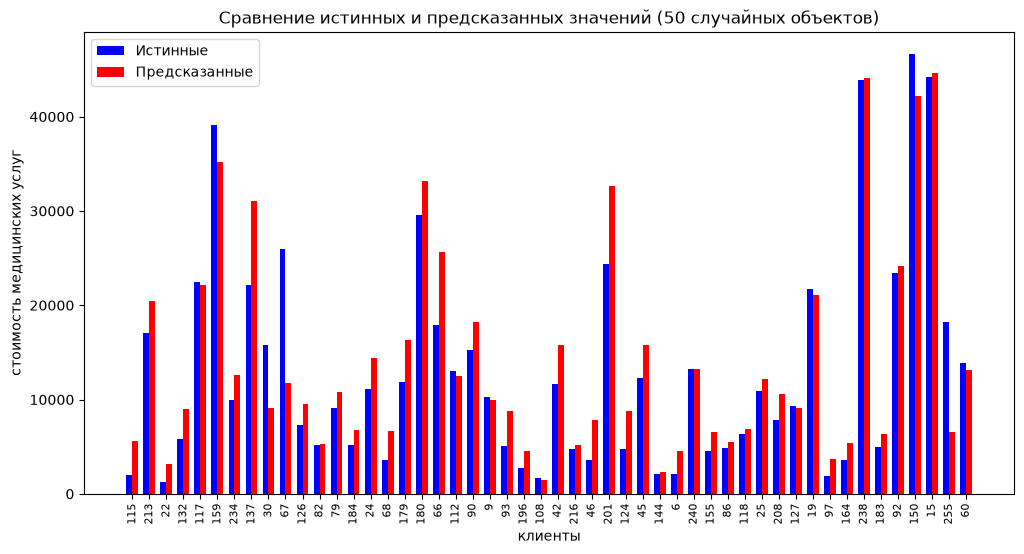

In [15]:
bar_plot_comparison(y_test, y_pred, 50)

**Наблюдения:**
* из 50 случайных образцов только очень редкие предсказания близки к истинным значениям
* нет единого тренда в отклонениях: есть образцы с ошибкой как в большую, так и в меньшую сторону

**Управление шумом**

Попробуем сгладить разброс и вариативность целевой переменной с помощью логарифмирования

In [16]:
def train_model_log(model, X_tr_sc, X_te_sc, y_tr):
    y_tr_log = np.log1p(y_tr)
    model.fit(X_tr_sc, y_tr_log)
    y_pr_log = model.predict(X_te_sc)
    return np.expm1(y_pr_log)

In [17]:
y_pred = train_model_log(best_knn, X_train_scaled, X_test_scaled, y_train)

In [18]:
print(f'Новый MSE на тесте: {mean_squared_error(y_test, y_pred):.2f}')

Новый MSE на тесте: 22544789.44


In [19]:
print_rmse_mae_mape(y_test, y_pred)

Root Mean Squared Error на тесте: 4748.14
Mean Absolute Error на тесте: 2429.36
Mean Absolute Percentage Error на тесте: 0.2135


**Применение логарифмирования привело к значительному снижению средней ошибки: с 34-35% до 21%!**

Попробуем также для улучшения алгоритма обучения исключить из тренировочных данных аномальные образцы. Сделаем это при помощи алгоритма IsolationForest 

In [20]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.05, random_state=42)

In [21]:
good_rows = iso.fit_predict(X_train) == 1

X_train_clean = X_train_scaled[good_rows]
y_train_clean = y_train[good_rows]

In [22]:
y_pred = train_model_log(best_knn, X_train_clean, X_test_scaled, y_train_clean)

In [23]:
print_rmse_mae_mape(y_test, y_pred)

Root Mean Squared Error на тесте: 4801.41
Mean Absolute Error на тесте: 2498.92
Mean Absolute Percentage Error на тесте: 0.2158


**Применение IsolationForest не улучшило результат.**

Попробуем найти лучшие гиперпараметры для неизменённых признаков и логарифмического преобразования целевой переменной

In [24]:
param_grid_knn['n_neighbors'] = [5, 7, 9, 11, 15, 21]
best_knn_log, y_pred_log = call_grid_search(knn, param_grid_knn, X_train_scaled, X_test_scaled, np.log1p(y_train), 'neg_mean_squared_error')
y_pred = np.expm1(y_pred_log)

Наилучшие параметры: {'metric': 'minkowski', 'n_neighbors': 15, 'p': 1, 'weights': 'uniform'}
Наилучший score на кроссвалидации: 0.17 (score: neg_mean_squared_error)


In [25]:
print_rmse_mae_mape(y_test, y_pred)

Root Mean Squared Error на тесте: 4863.85
Mean Absolute Error на тесте: 2496.90
Mean Absolute Percentage Error на тесте: 0.2078


Получаем также примерно **21%** средней ошибки.

**Эксперимент:** уберём колонки признак пола (sex_male и sex_female) из данных

In [26]:
df_no_region.head(3)

,age,bmi,children,smoker,charges,sex_female,sex_male
0,19,27.90,0,1,16884.9240,1.0,0.0
1,18,33.77,1,0,1725.5523,0.0,1.0
2,28,33.00,3,0,4449.4620,0.0,1.0


In [27]:
X_no_sex = df_no_region.drop(columns=['charges', 'sex_female', 'sex_male']).values
y_no_sex = df_no_region['charges'].values

In [28]:
X_train_ns, X_test_ns, y_train_ns, y_test_ns = train_test_split(X_no_sex, y_no_sex, test_size=0.2, random_state=42)

In [29]:
X_train_ns_scaled, X_test_ns_scaled = scale_X_data(X_train_ns, X_test_ns)

среднее масштабированных тестовых данных: -0.0074674188171898505, дисперсия: 0.9946172431396595


In [30]:
param_grid_knn['n_neighbors'] = [3, 5, 7, 9, 11, 15, 21, 31]
best_knn_ns, y_pred_log_ns = call_grid_search(knn, param_grid_knn, X_train_ns_scaled, X_test_ns_scaled, np.log1p(y_train_ns), 'neg_mean_squared_error')
y_pred_ns = np.expm1(y_pred_log_ns)

Наилучшие параметры: {'metric': 'minkowski', 'n_neighbors': 31, 'p': 2, 'weights': 'uniform'}
Наилучший score на кроссвалидации: 0.16 (score: neg_mean_squared_error)


In [31]:
print_rmse_mae_mape(y_test_ns, y_pred_ns)

Root Mean Squared Error на тесте: 4586.62
Mean Absolute Error на тесте: 2315.07
Mean Absolute Percentage Error на тесте: 0.1960


Оказалось, что без признака пола результат даже несколько лучше: средняя ошибка **20%**

Добавим больше значений для количества соседей в сетку

In [32]:
param_grid_knn['n_neighbors'] = [3, 5, 7, 9, 11, 15, 21, 25, 27, 29, 31, 33, 35]
best_knn_ns, y_pred_log_ns = call_grid_search(knn, param_grid_knn, X_train_ns_scaled, X_test_ns_scaled, np.log1p(y_train_ns), 'neg_mean_squared_error')
y_pred_ns = np.expm1(y_pred_log_ns)

Наилучшие параметры: {'metric': 'minkowski', 'n_neighbors': 29, 'p': 1, 'weights': 'uniform'}
Наилучший score на кроссвалидации: 0.16 (score: neg_mean_squared_error)


In [33]:
print_rmse_mae_mape(y_test_ns, y_pred_ns)

Root Mean Squared Error на тесте: 4666.67
Mean Absolute Error на тесте: 2393.96
Mean Absolute Percentage Error на тесте: 0.2013


Новая модель имеет примерно те же показатели

Посмотрим, насколько визуально приближение модели отличается от истинных значений.

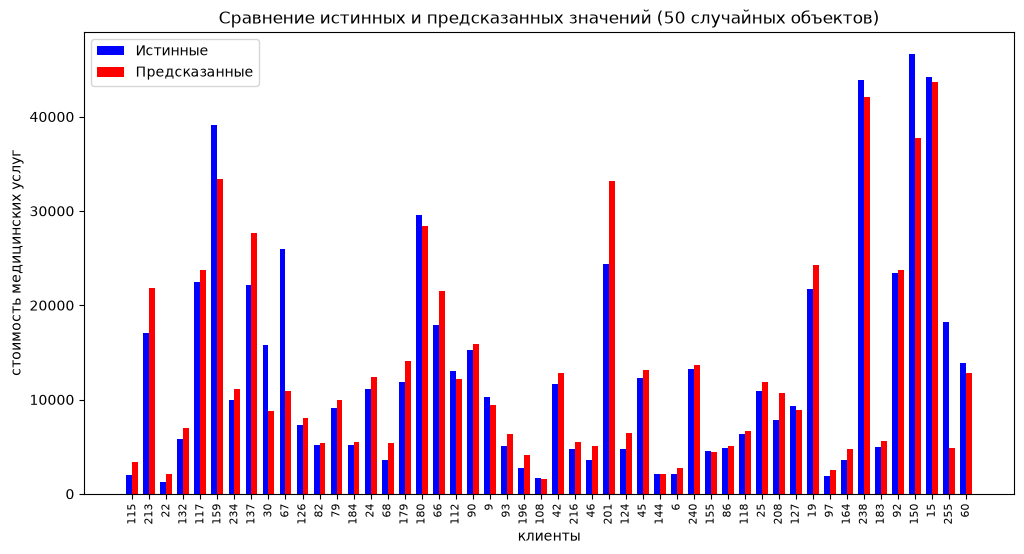

In [34]:
bar_plot_comparison(y_test, y_pred, 50)

Визуально, картина примерно такая же, как и для первой KNN модели

<h4>Модель Random Forest Regressor</h4>

In [35]:
from sklearn.ensemble import RandomForestRegressor

param_grid_rf = {
    'n_estimators': [50, 100, 200],      # Количество деревьев в лесу
    'max_depth': [None, 5, 10, 15],       # Максимальная глубина деревьев
    'min_samples_split': [2, 5, 10],      # Минимальное число объектов для сплита в узле
    'min_samples_leaf': [1, 2, 4],        # Минимальное число объектов в листе
    'max_features': [1.0, 'sqrt']         # Количество признаков для выбора лучшего сплита
}

rf_reg = RandomForestRegressor(random_state=42)
best_randf, y_pred_log = call_grid_search(rf_reg, param_grid_rf, X_train_scaled, X_test_scaled, np.log1p(y_train), 'neg_mean_squared_error')
y_pred = np.expm1(y_pred_log)

Наилучшие параметры: {'max_depth': 5, 'max_features': 1.0, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 50}
Наилучший score на кроссвалидации: 0.15 (score: neg_mean_squared_error)


In [36]:
print_rmse_mae_mape(y_test, y_pred)

Root Mean Squared Error на тесте: 4398.98
Mean Absolute Error на тесте: 2054.19
Mean Absolute Percentage Error на тесте: 0.1760


In [37]:
param_grid_rf['n_estimators'] = [10, 20, 30, 50, 100]
param_grid_rf['max_depth'] = [None, 2, 3, 5, 10, 15]

best_randf, y_pred_log = call_grid_search(rf_reg, param_grid_rf, X_train_scaled, X_test_scaled, np.log1p(y_train), 'neg_mean_squared_error')
y_pred = np.expm1(y_pred_log)
print_rmse_mae_mape(y_test, y_pred)

Наилучшие параметры: {'max_depth': 5, 'max_features': 1.0, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 20}
Наилучший score на кроссвалидации: 0.15 (score: neg_mean_squared_error)
Root Mean Squared Error на тесте: 4399.10
Mean Absolute Error на тесте: 2036.60
Mean Absolute Percentage Error на тесте: 0.1758


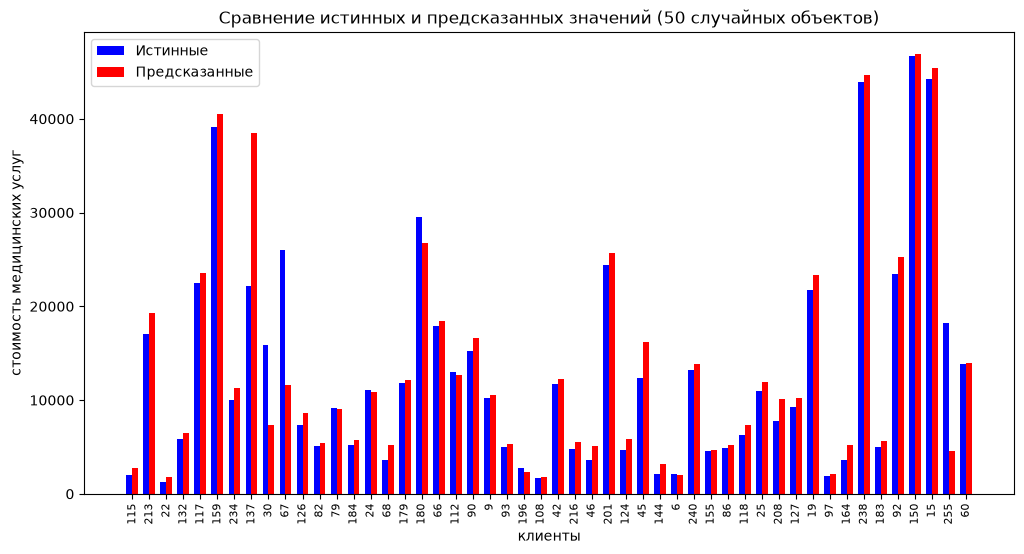

In [38]:
bar_plot_comparison(y_test, y_pred, 50)

Проверим также на данных, из которых удалён признак пола

In [39]:
best_randf_ns, y_pred_log_ns = call_grid_search(rf_reg, param_grid_rf, X_train_ns_scaled, X_test_ns_scaled, np.log1p(y_train_ns), 'neg_mean_squared_error')
y_pred_ns = np.expm1(y_pred_log_ns)
print_rmse_mae_mape(y_test_ns, y_pred_ns)

Наилучшие параметры: {'max_depth': 5, 'max_features': 1.0, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 50}
Наилучший score на кроссвалидации: 0.15 (score: neg_mean_squared_error)
Root Mean Squared Error на тесте: 4407.85
Mean Absolute Error на тесте: 2087.51
Mean Absolute Percentage Error на тесте: 0.1843


Для решающих деревьев дополнительный признак только в плюс. Оставляем его.

Итак, лучший результат, что удалось получить с Random Forest Regressor: средняя ошибка (метрика MAPE): около **18%**

<h4>Модель Gradient Boosting Regressor</h4>

In [40]:
from sklearn.ensemble import GradientBoostingRegressor

gb_reg = GradientBoostingRegressor(random_state=42)

param_grid_gb = {
    "n_estimators": [20, 30, 50, 100],  # Количество деревьев
    "learning_rate": [0.01, 0.1, 0.2],  # Скорость обучения
    "max_depth": [None, 2, 3, 5, 10],  # Максимальная глубина деревьев
    "subsample": [0.8, 1.0],  # Доля выборки для построения каждого дерева
}

best_gb, y_pred_log = call_grid_search(gb_reg, param_grid_gb, X_train_scaled, X_test_scaled, np.log1p(y_train), 'neg_mean_squared_error')
y_pred = np.expm1(y_pred_log)
print_rmse_mae_mape(y_test, y_pred)

Наилучшие параметры: {'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 20, 'subsample': 1.0}
Наилучший score на кроссвалидации: 0.15 (score: neg_mean_squared_error)
Root Mean Squared Error на тесте: 4425.67
Mean Absolute Error на тесте: 2021.06
Mean Absolute Percentage Error на тесте: 0.1768


Пока что прежние **18%**.  
Напоминаю, что основная сложность работы с данным набором &ndash; большая вариантивность целевой переменной: половина данных не превосходит 10 000, а другая половина распределена неравномерно по интервалу шириной более 50 000.

Для тренировки модели Gradient Boosting можно использовать параметр loss = 'huber'. Тогда при обучении на сетке с кросс валидацией модель будет использовать специальную метрику, которая не так сильно штрафует на высоких значениях, как метрика среднеквадратичной ошибки.

In [41]:
param_grid_gb['loss'] = ['squared_error', 'huber']

best_gb, y_pred_log = call_grid_search(gb_reg, param_grid_gb, X_train_scaled, X_test_scaled, np.log1p(y_train), 'neg_mean_squared_error')
y_pred = np.expm1(y_pred_log)
print_rmse_mae_mape(y_test, y_pred)

Наилучшие параметры: {'learning_rate': 0.1, 'loss': 'huber', 'max_depth': 3, 'n_estimators': 30, 'subsample': 0.8}
Наилучший score на кроссвалидации: 0.15 (score: neg_mean_squared_error)
Root Mean Squared Error на тесте: 4524.17
Mean Absolute Error на тесте: 1878.29
Mean Absolute Percentage Error на тесте: 0.1405


С помощью huber получаем значительное улучшение на метриках MAE и MAPE: средняя ошибка **14%**
Действительно, использование пороговой оценки 'huber' помогает сохранить хорошую точность на всём диапазоне: и на среднестатистических значениях, и на экстремальных.

Построим на одной диаграмме предсказанные и истинные значения

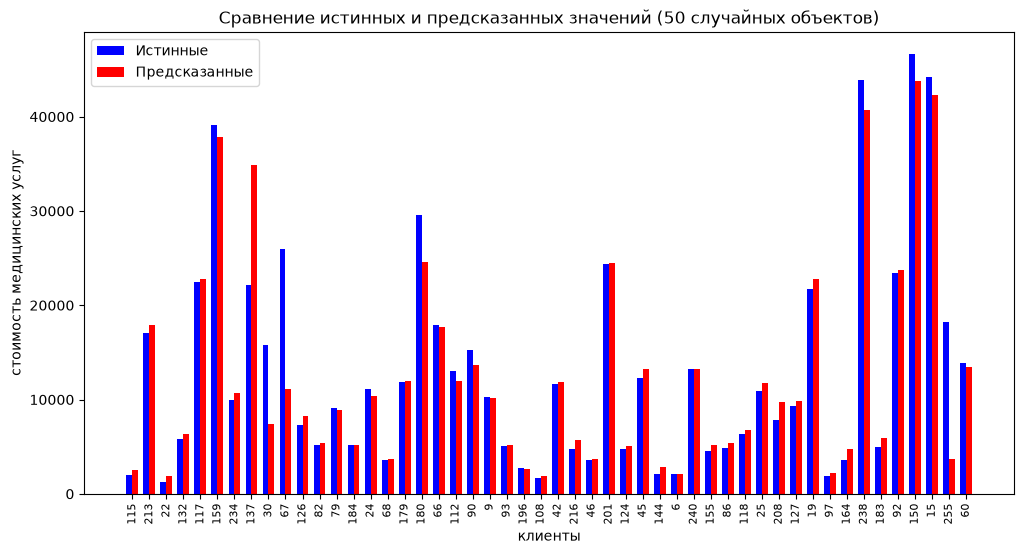

In [42]:
bar_plot_comparison(y_test, y_pred, 50)

Присмотримся подробнее к лучшим и худшим прогнозам из выборки

In [43]:
df_droped = df_no_region.drop(columns=['charges'])

In [44]:
df_droped.head(3)

,age,bmi,children,smoker,sex_female,sex_male
0,19,27.90,0,1,1.0,0.0
1,18,33.77,1,0,0.0,1.0
2,28,33.00,3,0,0.0,1.0


In [45]:
def concat_X_y_to_compare(df_, X_te, y_te, y_pr):
    column_names = df_.columns.to_list()
    X_te_df = pd.DataFrame(X_te, columns=column_names)
    y_te_series = pd.Series(y_te, index=X_te_df.index, name='charges_true')
    y_pr_series = pd.Series(y_pr, index=X_te_df.index, name='charges_pred')
    return pd.concat([X_te_df, y_te_series, y_pr_series], axis=1)

In [46]:
compare_df = concat_X_y_to_compare(df_droped, X_test, y_test, y_pred)

In [47]:
bad_scored_indices = [137, 30, 67, 180, 238, 255]

In [48]:
bad_scored_df = compare_df.iloc[bad_scored_indices]

In [49]:
bad_scored_df

,age,bmi,children,smoker,sex_female,sex_male,charges_true,charges_pred
137,42.0,30.00,0.0,1.0,0.0,1.0,22144.03200,34874.215649
30,40.0,29.30,4.0,0.0,1.0,0.0,15828.82173,7446.955045
67,52.0,26.40,3.0,0.0,0.0,1.0,25992.82104,11163.525058
180,63.0,27.74,0.0,1.0,1.0,0.0,29523.16560,24566.233692
238,42.0,40.37,2.0,1.0,1.0,0.0,43896.37630,40750.297400
255,25.0,32.23,1.0,0.0,1.0,0.0,18218.16139,3697.983934


Видим, что, например, номера:
* 137: мужчина, 42 года, bmi 30 (выше нормы, но ещё не ожирение), детей не имеет, курит: оценка почти в 35 000 при реальных затратах примерно 22 000
* 30: женщина, 40 лет, bmi ~30, четверо детей, не курит: оценка *занижена* в два раза
* 67: мужчина, 52 года, bmi 26.4, трое детей, не курит: оценка *занижена* более чем вдвое
* 180: женщина, 63 года, bmi ~28, детей не имеет, курит, оценка *занижена*
* 238: женщина, 42 года, bmi более 40 (ожирение), двое детей, курит, оценка *занижена*
* 255: женщина, 25 лет, bmi более 30, один ребёнок, оценка *занижена* в 5-6 раз

In [50]:
print(f'В сумме модель ошибается в оценке на {np.sum(y_pred - y_test).round(2)} на {y_test.size} образах')

В сумме модель ошибается в оценке на -285234.82 на 268 образах


In [51]:
best_scored_indices = [79, 184, 196, 6, 60]

In [52]:
best_scored_df = compare_df.iloc[best_scored_indices]
best_scored_df

,age,bmi,children,smoker,sex_female,sex_male,charges_true,charges_pred
79,45.0,25.700,3.0,0.0,1.0,0.0,9101.79800,8941.490257
184,29.0,22.515,3.0,0.0,0.0,1.0,5209.57885,5160.388998
196,19.0,24.510,1.0,0.0,1.0,0.0,2709.11190,2586.565317
6,19.0,22.515,0.0,0.0,1.0,0.0,2117.33885,2125.054486
60,63.0,31.800,0.0,0.0,1.0,0.0,13880.94900,13450.603985


Посмотрим внимательнее на случаи успешной оценки целевой переменной:
* 79: женщина, 45 лет, нормальный bmi, трое детей, не курит, затраты на медицинские услуги чуть ниже медианного значения
* 184: мужчина, 29 лет, нормальный bmi, трое детей, не курит, затраты на медицинские услуги в районе первого квартиля
* 196: женщина, 19 лет, нормальный bmi, один ребёнок, не курит, затраты на медицинские услуги около 2700
* 6: женщина, 19 лет, нормальный bmi, детей нет, не курит, затраты на медицинские услуги около 2000
* 60: женщина, 63 года, bmi больше 30, не курит, затраты около 14000

Пять случаев выше &ndash; это случаи относительно невысоких затрат &ndash; только одно значение превосходит среднее.

Пока предварительно можно заключить, что модель чаще ошибается на более сложных случаях: высокий bmi, статус курильщика &ndash; случаях, о которых у нас, похоже, недостаточно данных: возможно, имеют место хронические заболевания, сложные роды в прошедший период, осложнения заболеваний, перенесённые операции и т.д.

Можно более пристально на всей тестовой выборке изучить группу людей с высоким процентом отклонения от истинного значения. Однако, сейчас мы в эту задачу погружаться не будем.

Попробуем подобрать с помощью GridSearchCV с loss='huber' дополнительный пороговый параметр alpha

In [53]:
param_grid_gb

{'n_estimators': [20, 30, 50, 100],
 'learning_rate': [0.01, 0.1, 0.2],
 'max_depth': [None, 2, 3, 5, 10],
 'subsample': [0.8, 1.0],
 'loss': ['squared_error', 'huber']}

In [54]:
param_grid_gb['n_estimators'] = [20, 30, 50]
param_grid_gb['max_depth'] = [None, 2, 3, 5]
param_grid_gb['loss'] = ['huber']
param_grid_gb['alpha'] = [0.9, 0.92, 0.93, 0,94, 0.95, 0.96, 0.97, 0.98]

#best_gb, y_pred_log = call_grid_search(gb_reg, param_grid_gb, X_train_scaled, X_test_scaled, np.log1p(y_train), 'neg_mean_squared_error')
#y_pred = np.expm1(y_pred_log)
#print_rmse_mae_mape(y_test, y_pred)

Были найдены следующие значения:

Наилучшие параметры: {'alpha': 0.92, 'learning_rate': 0.1, 'loss': 'huber', 'max_depth': 3, 'n_estimators': 30, 'subsample': 0.8}  
Наилучший CV MSE: 0.1453  
Root Mean Squared Error на тесте: 4546.1973  
Mean Absolute Error на тесте: 1948.1943  
Mean Absolute Percentage Error на тесте: 0.1491

Что не улучшает результатов предыдущего эксперимента

Проведём ещё один эксперимент: **возвратим данные по региону.**

In [55]:
df.head(3)

,age,bmi,children,smoker,charges,region,sex_female,sex_male,region_northeast,region_northwest,region_southeast,region_southwest
0,19,27.90,0,1,16884.9240,3,1.0,0.0,0.0,0.0,0.0,1.0
1,18,33.77,1,0,1725.5523,2,0.0,1.0,0.0,0.0,1.0,0.0
2,28,33.00,3,0,4449.4620,2,0.0,1.0,0.0,0.0,1.0,0.0


In [56]:
X_full = df.drop(columns=['charges', 'region']).values
y_full = df['charges'].values

In [57]:
X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(X_full, y_full, test_size=0.2, random_state=42)

X_train_full_scaled, X_test_full_scaled = scale_X_data(X_train_full, X_test_full)

среднее масштабированных тестовых данных: -0.003107899587482606, дисперсия: 0.9978235061169132


In [58]:
param_grid_gb

{'n_estimators': [20, 30, 50],
 'learning_rate': [0.01, 0.1, 0.2],
 'max_depth': [None, 2, 3, 5],
 'subsample': [0.8, 1.0],
 'loss': ['huber'],
 'alpha': [0.9, 0.92, 0.93, 0, 94, 0.95, 0.96, 0.97, 0.98]}

In [59]:
del param_grid_gb['alpha']

In [60]:
param_grid_gb

{'n_estimators': [20, 30, 50],
 'learning_rate': [0.01, 0.1, 0.2],
 'max_depth': [None, 2, 3, 5],
 'subsample': [0.8, 1.0],
 'loss': ['huber']}

In [61]:
param_grid_gb['n_estimators'] = [20, 30, 50, 100]
param_grid_gb['max_depth'] = [None, 2, 3, 5, 10]
param_grid_gb

{'n_estimators': [20, 30, 50, 100],
 'learning_rate': [0.01, 0.1, 0.2],
 'max_depth': [None, 2, 3, 5, 10],
 'subsample': [0.8, 1.0],
 'loss': ['huber']}

In [62]:
best_gb_full, y_pred_log_full = call_grid_search(gb_reg, param_grid_gb, X_train_full_scaled, X_test_full_scaled, np.log1p(y_train_full), 'neg_mean_squared_error')
y_pred_full = np.expm1(y_pred_log_full)
print_rmse_mae_mape(y_test_full, y_pred_full)

Наилучшие параметры: {'learning_rate': 0.1, 'loss': 'huber', 'max_depth': 3, 'n_estimators': 50, 'subsample': 0.8}
Наилучший score на кроссвалидации: 0.14 (score: neg_mean_squared_error)
Root Mean Squared Error на тесте: 4404.19
Mean Absolute Error на тесте: 1636.71
Mean Absolute Percentage Error на тесте: 0.1046


Итак, удалось улучшить показатели! Теперь средняя ошибка всего **10%**

Посмотрим на визуальные отличия прогноза от истинных данных

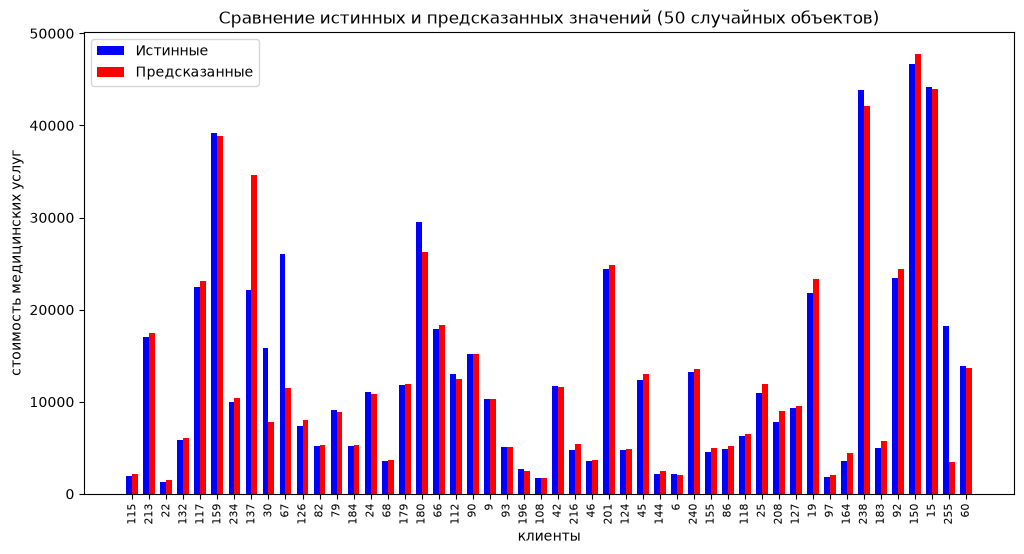

In [63]:
bar_plot_comparison(y_test_full, y_pred_full, 50)

In [64]:
df_region = df.drop(columns=['region', 'charges'])
df_region.head(3)

,age,bmi,children,smoker,sex_female,sex_male,region_northeast,region_northwest,region_southeast,region_southwest
0,19,27.90,0,1,1.0,0.0,0.0,0.0,0.0,1.0
1,18,33.77,1,0,0.0,1.0,0.0,0.0,1.0,0.0
2,28,33.00,3,0,0.0,1.0,0.0,0.0,1.0,0.0


In [65]:
compare_df_region = concat_X_y_to_compare(df_region, X_test_full, y_test_full, y_pred_full)

In [66]:
display(compare_df_region.iloc[bad_scored_indices])

,age,bmi,children,smoker,sex_female,sex_male,region_northeast,region_northwest,region_southeast,region_southwest,charges_true,charges_pred
137,42.0,30.00,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,22144.03200,34638.975594
30,40.0,29.30,4.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,15828.82173,7816.013864
67,52.0,26.40,3.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,25992.82104,11438.460024
180,63.0,27.74,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,29523.16560,26303.388678
238,42.0,40.37,2.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,43896.37630,42106.835561
255,25.0,32.23,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,18218.16139,3495.210226


Если сравнивать предсеказания модели по "худшим индексам" прошлой модели: оценки по 180 и 238 удалось несколько улучшить

In [67]:
display(compare_df_region.iloc[best_scored_indices])

,age,bmi,children,smoker,sex_female,sex_male,region_northeast,region_northwest,region_southeast,region_southwest,charges_true,charges_pred
79,45.0,25.700,3.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,9101.79800,8834.864285
184,29.0,22.515,3.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,5209.57885,5283.329135
196,19.0,24.510,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,2709.11190,2485.459630
6,19.0,22.515,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,2117.33885,2028.712008
60,63.0,31.800,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,13880.94900,13616.567721


In [68]:
def bar_plot_compare_predictions(y_te, y_pr1, y_pr2, indices, labels):
    fig, ax = plt.subplots(figsize=(12, 6))
    n = len(indices)
    x = np.arange(n)
    w = 0.2

    rects1 = ax.bar(x - w, y_te[indices], w, label=labels['test'], color='blue')
    rects2 = ax.bar(x, y_pr1[indices], w, label=labels['pred1'], color='red')
    rects3 = ax.bar(x + w, y_pr2[indices], w, label=labels['pred2'], color='green')

    ax.set_title(f'Сравнение предсказанных значений двух моделей')
    ax.set_xlabel('клиенты')
    ax.set_ylabel('стоимость медицинских услуг')

    ax.set_xticks(x)
    ax.set_xticklabels(indices, rotation=90, fontsize=8)

    ax.legend()

In [69]:
lbl = {
    'test': 'Истинные',
    'pred1': 'предсказания модели без учёта региона',
    'pred2': 'соответствующие предсказания модели с учётом региона'
}

In [70]:
np.random.seed(42)
n_all = len(y_test)
random_indices = np.random.choice(n_all, size=50, replace=False)

Сравним два последних прогноза

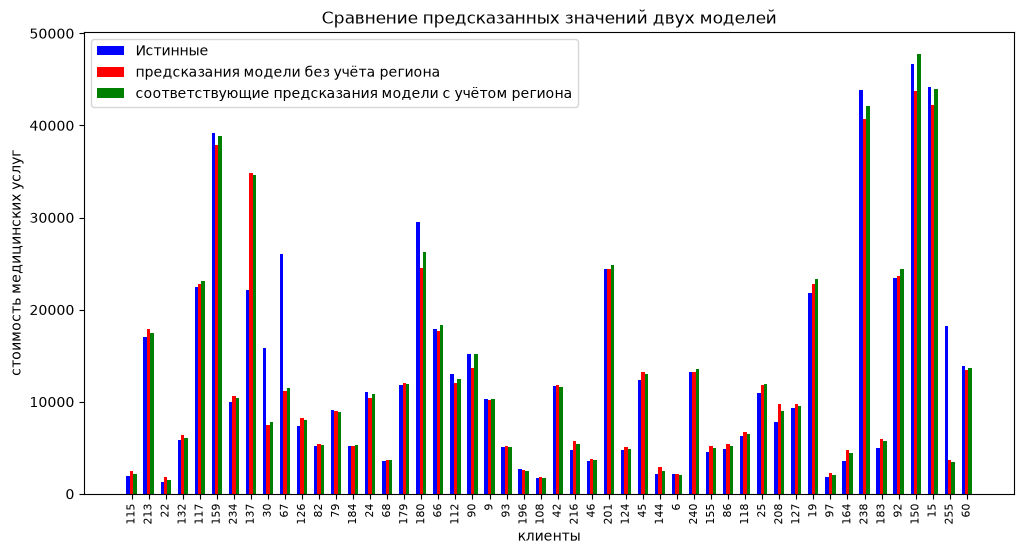

In [71]:
bar_plot_compare_predictions(y_test, y_pred, y_pred_full, random_indices, lbl)

In [72]:
lbl['pred1'] = 'ошибочные предсказания модели без учёта региона'

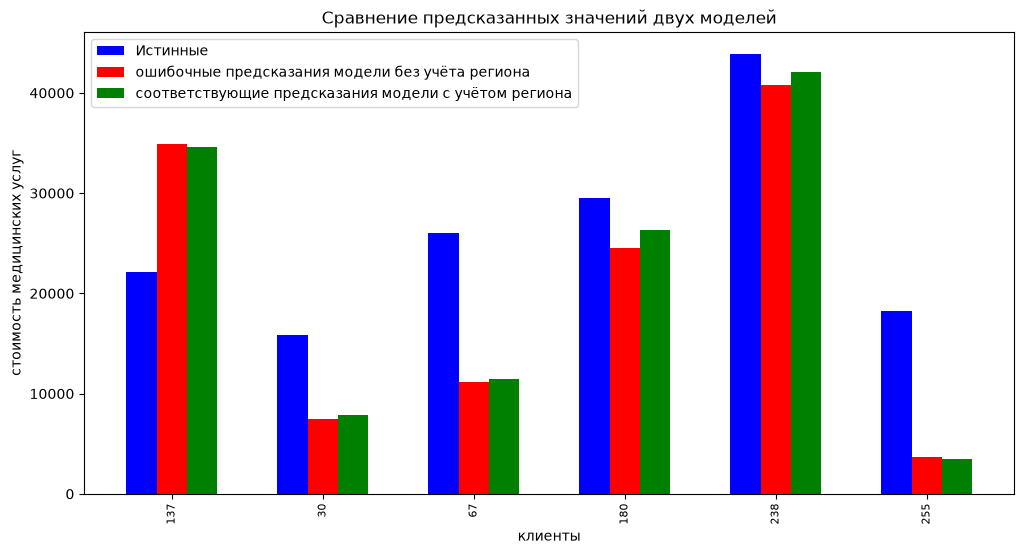

In [73]:
bar_plot_compare_predictions(y_test, y_pred, y_pred_full, bad_scored_indices, lbl)

Видим, что **аномалии** остаются плохо предсказуемыми. Нужны дополнительные сведения о клиентах и их здоровье

In [74]:
lbl['pred1'] = 'лучшие предсказания модели без учёта региона'

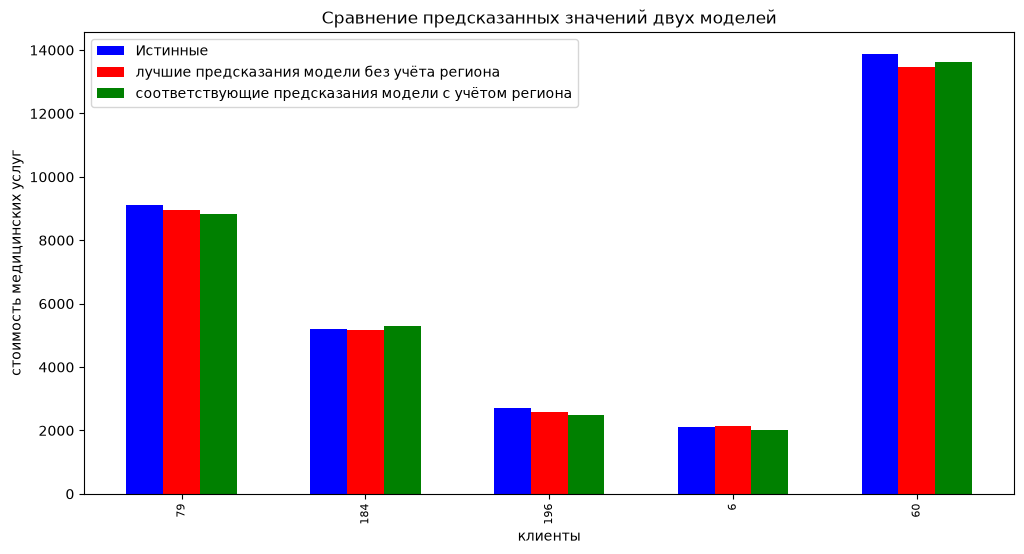

In [75]:
bar_plot_compare_predictions(y_test, y_pred, y_pred_full, best_scored_indices, lbl)

Видно, что модель ошибается как в большую, так и в меньшую сторону.

In [76]:
all_test_costs = int(np.sum(y_test_full))
err_full = int(np.sum(y_pred_full - y_test_full))
fs_sum_error = f'В сумме модель ошибается в оценке на {err_full:_} на {y_test_full.size} образах при общей сумме затрат на этих образцах: {all_test_costs:_}'
fs_sum_error = fs_sum_error.replace('_', ' ')
print(fs_sum_error)

В сумме модель ошибается в оценке на -257 953 на 268 образах при общей сумме затрат на этих образцах: 3 475 508


Сохраним итоговую модель

In [77]:
import pickle

filename = 'medical_costs_prognosis_model.pkl'
pickle.dump(best_gb_full, open(filename, 'wb'))

<h4>Анализ результатов и выводы</h4>

Задача прогнозирования решена.

In [78]:
med = np.quantile(df['charges'].values, q=0.5)
mae_full = mean_absolute_error(y_test_full, y_pred_full)
mape_full = mean_absolute_percentage_error(y_test_full, y_pred_full)
print(f'При медианном значении стоимости медицинских услуг {med:.0f} средняя ошибка на всей выборке {mae_full:.0f}, средний процент ошибки {mape_full:.2%}')

При медианном значении стоимости медицинских услуг 9382 средняя ошибка на всей выборке 1637, средний процент ошибки 10.46%


Модель ошибается как в большую, так и в меньшую сторону.

In [79]:
print(fs_sum_error)

В сумме модель ошибается в оценке на -257 953 на 268 образах при общей сумме затрат на этих образцах: 3 475 508


**Возможности для улучшения модели**

Рекомендуем заказчику &ndash; страховой компании собирать и передавать для обучения больше сведений о клиентах касающихся их жизни и здоровья:
* информация о хронических заболеваниях (например, диабет)
* информация о тяжести родов (для женщин)
* род деятельности, профессия
* увлечение экстремальными видами спорта

**Что можно сделать ещё на данной выборке:**
* внимательнее проанализировать группу тестовой выборки, по которой мы получаем большие расхождения прогноза и истинного значения; сделать выводы, можно ли как-то улучшить модель или мы имеем дело с *аномалиями*, которые никак не объясняются имеющимися данными
* можно провести ещё такой эксперимент: категоризировать признак bmi в соответствии со стандартами нормы индекса массы тела